# ASL Citizen SLR — Green Computing, Notebook 6/5: Cross-Model Aggregation

**Course:** CSE 407 — Green Computing
**Paper:** *Quantifying the Carbon Cost of Accuracy: An Energy-Aware Comparison of CNN, Transformer,
and Hybrid Architectures for Word-Level Sign Language Recognition*

This notebook is the **aggregation step** for the five-model family. It does not train anything —
it loads the `green_metrics_*.json` model cards produced by the other five notebooks
(MobileNetV3-Small, ResNet-50, ViViT-Lite, TimeSformer, TinyMSLR-hybrid) and builds every
cross-model table and figure the paper needs:

- The revised **Table 1** (multi-seed mean ± SD across all five models)
- **Figure 1** — accuracy vs. training CO2e, with seed-variance error bars
- **Figure 2** — accuracy-per-carbon efficiency (η_train), with error bars
- **Figure 3** — TinyMSLR-hybrid fusion-gate collapse
- The **deployment-volume sensitivity table** (η_life stability across 10k/100k/1M inferences)
- The **accuracy-threshold sensitivity table** (50%/60%/70%)
- The **signer-independence** and **hardware/software environment** summary (shared across all 5)
- The **within-family marginal-carbon-cost-per-accuracy-point** calculation (CNN vs. Transformer)

**Output layout.** Everything is written under `CONFIG.OUTPUT_DIR/metadata_results/`, split into
two subfolders so results can be handed off cleanly:
- `metadata_results/tables/` — every CSV table, consistently named
- `metadata_results/images/` — every figure, saved as both `.png` (300 DPI, for quick viewing)
  and `.pdf` (vector, for direct inclusion in a LaTeX paper)

**Figure style.** All figures use an IEEE-paper-style serif font stack (Times-like, via
matplotlib's `mathtext.fontset="stix"` — no external LaTeX install required on Kaggle) and
collision-avoided text labels so annotations don't overlap the data or each other.

Run this only after all five model-family notebooks have been executed and their JSON model
cards downloaded into one folder.

## 1. Setup & Imports

In [1]:
import json
import statistics as stats
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

# --- adjustText: used in Figure 1 to keep the five model-name labels from overlapping
# each other or the data points. Not preinstalled on Kaggle -- installed on demand, with
# a manual-offset fallback (Section 6) if the install fails (e.g. no internet toggle). ---
try:
    from adjustText import adjust_text
    ADJUST_TEXT_AVAILABLE = True
except ImportError:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "adjustText"], check=True)
        from adjustText import adjust_text
        ADJUST_TEXT_AVAILABLE = True
    except Exception as e:
        print(f"adjustText unavailable ({e}) -- Figure 1 will fall back to manual label offsets.")
        ADJUST_TEXT_AVAILABLE = False

# --- IEEE-paper-style plotting defaults ---------------------------------------------------
# Serif font stack (Times-like) with a matching math font (STIX mirrors Times' math glyphs)
# so figures visually match an IEEE two-column paper without requiring a system LaTeX install
# (which Kaggle sessions don't have by default). Set text.usetex=True below instead if your
# environment does have a working LaTeX install and you want the real thing.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,  # flip to True only if a working LaTeX install is confirmed present
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "figure.dpi": 130,      # on-screen preview only -- saved files use savefig.dpi below
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,     # embed as scalable TrueType, not raster, for clean LaTeX inclusion
    "ps.fonttype": 42,
})
# NOTE: seaborn's set_style() resets font.family (to sans-serif) as a side effect, so it
# must run BEFORE the rcParams.update above is applied, not after -- reasserting the IEEE
# font settings here guards against that ordering mistake regardless of cell edit order.
sns.set_style("ticks")
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
})

print(f"adjustText available: {ADJUST_TEXT_AVAILABLE}")
print("Aggregation notebook ready. Point CONFIG.MODEL_CARDS_DIR at the folder containing")
print("all five green_metrics_*.json files before running the next cell.")


adjustText available: True
Aggregation notebook ready. Point CONFIG.MODEL_CARDS_DIR at the folder containing
all five green_metrics_*.json files before running the next cell.


## 2. Configuration

Update `MODEL_CARDS_DIR` to wherever you downloaded the five JSON files from each notebook's
`/kaggle/working/green_report_<model_tag>/` output folder (Kaggle does not persist `/kaggle/working`
between sessions, so these must be downloaded and re-uploaded here, e.g. as a Kaggle Dataset or
just alongside this notebook).

Every output this notebook produces goes under `OUTPUT_DIR/metadata_results/`, split into a
`tables/` folder (CSV + Markdown) and an `images/` folder (PNG + PDF per figure) — this is the
one folder you hand off when the paper needs the results.

In [2]:
class CONFIG:
    # Folder containing all five green_metrics_*.json files (flat, no subfolders needed --
    # this notebook globs for them by filename pattern).
    MODEL_CARDS_DIR = Path("/kaggle/input/datasets/tonimaislamlamia/agregrated-results/aggregrated_results")

    # Fallback used only if MODEL_CARDS_DIR is empty (e.g. running this notebook standalone
    # without the other five already run) -- lets every cell below still execute end-to-end
    # for a sanity check, using the model cards this study actually produced.
    EXPECTED_MODEL_TAGS = [
        "mobilenet_v3_small_cnn_light",
        "resnet50_cnn_heavy",
        "vivit_lite_transformer_light",
        "timesformer_base_transformer_heavy",
        "tinymslr_hybrid_no_kd",
    ]

    OUTPUT_DIR = Path("/kaggle/working/green_report_aggregated")
    METADATA_DIR = OUTPUT_DIR / "metadata_results"
    TABLES_DIR = METADATA_DIR / "tables"
    IMAGES_DIR = METADATA_DIR / "images"


for _d in (CONFIG.OUTPUT_DIR, CONFIG.METADATA_DIR, CONFIG.TABLES_DIR, CONFIG.IMAGES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print(f"Looking for model cards in: {CONFIG.MODEL_CARDS_DIR}")
print(f"Expected {len(CONFIG.EXPECTED_MODEL_TAGS)} model cards: {CONFIG.EXPECTED_MODEL_TAGS}")
print(f"\nOutputs will be written to:")
print(f"  Tables: {CONFIG.TABLES_DIR}")
print(f"  Images: {CONFIG.IMAGES_DIR}")


def save_table(df, name, index=True):
    # Saves a DataFrame as CSV into CONFIG.TABLES_DIR with a consistent name and prints
    # the saved path -- the single choke point every table in this notebook goes through.
    path = CONFIG.TABLES_DIR / f"{name}.csv"
    df.to_csv(path, index=index)
    print(f"Saved table: {path}")
    return path


def save_figure(fig, name):
    # Saves a Matplotlib figure as both PNG (300 DPI, quick viewing) and PDF (vector,
    # for direct \includegraphics in the LaTeX paper) into CONFIG.IMAGES_DIR.
    png_path = CONFIG.IMAGES_DIR / f"{name}.png"
    pdf_path = CONFIG.IMAGES_DIR / f"{name}.pdf"
    fig.savefig(png_path)
    fig.savefig(pdf_path)
    print(f"Saved figure: {png_path}")
    print(f"Saved figure: {pdf_path}")
    return png_path, pdf_path


Looking for model cards in: /kaggle/input/datasets/tonimaislamlamia/agregrated-results/aggregrated_results
Expected 5 model cards: ['mobilenet_v3_small_cnn_light', 'resnet50_cnn_heavy', 'vivit_lite_transformer_light', 'timesformer_base_transformer_heavy', 'tinymslr_hybrid_no_kd']

Outputs will be written to:
  Tables: /kaggle/working/green_report_aggregated/metadata_results/tables
  Images: /kaggle/working/green_report_aggregated/metadata_results/images


## 3. Load the Five Model Cards

Fails loudly (not silently) if a card is missing or malformed -- a partial five-model comparison
that silently drops a model is worse than an explicit error, since every downstream figure/table
in this notebook assumes exactly five cards are present.

In [3]:
def load_model_cards(cards_dir: Path, expected_tags):
    json_paths = sorted(cards_dir.glob("green_metrics_*.json"))
    if not json_paths:
        raise FileNotFoundError(
            f"No green_metrics_*.json files found in {cards_dir}. "
            "Download the model card JSON from each of the five model notebooks' "
            "OUTPUT_DIR and place them together in this folder before re-running."
        )

    cards = {}
    for p in json_paths:
        with open(p) as f:
            card = json.load(f)
        cards[card["model_tag"]] = card

    missing = set(expected_tags) - set(cards.keys())
    extra = set(cards.keys()) - set(expected_tags)
    if missing:
        raise ValueError(
            f"Missing model card(s) for: {sorted(missing)}. "
            f"Found: {sorted(cards.keys())}. All five must be present for a valid "
            "cross-model comparison -- partial comparisons are not written out below."
        )
    if extra:
        print(f"NOTE: found unexpected extra model card(s), ignoring: {sorted(extra)}")

    # Return in a fixed, paper-consistent family order (light CNN -> heavy CNN ->
    # light Transformer -> heavy Transformer -> hybrid), not JSON-load order.
    return {tag: cards[tag] for tag in expected_tags}


MODEL_CARDS = load_model_cards(CONFIG.MODEL_CARDS_DIR, CONFIG.EXPECTED_MODEL_TAGS)
print(f"Loaded {len(MODEL_CARDS)} model cards:")
for tag, card in MODEL_CARDS.items():
    n_seeds = card.get("multi_seed_summary", {}).get("n_seeds", "?")
    print(f"  {tag}: n_seeds={n_seeds}, test_top1_mean={card.get('test_top1_mean')}")


Loaded 5 model cards:
  mobilenet_v3_small_cnn_light: n_seeds=3, test_top1_mean=0.05701443103856163
  resnet50_cnn_heavy: n_seeds=3, test_top1_mean=0.5211734090371422
  vivit_lite_transformer_light: n_seeds=3, test_top1_mean=0.09392003785190442
  timesformer_base_transformer_heavy: n_seeds=3, test_top1_mean=0.5990063875088716
  tinymslr_hybrid_no_kd: n_seeds=3, test_top1_mean=0.34681807428436245


## 4. Table 1 (Revised) — Multi-Seed Cross-Model Comparison

Builds the paper's headline table directly from each model card's `multi_seed_summary` block --
mean ± SD across seeds, not the single-run figures the original submission relied on
(paper review Major Issue #2).

In [4]:
FAMILY_LABELS = {
    "mobilenet_v3_small_cnn_light": "CNN (light)",
    "resnet50_cnn_heavy": "CNN (heavy)",
    "vivit_lite_transformer_light": "Transformer (light)",
    "timesformer_base_transformer_heavy": "Transformer (heavy)",
    "tinymslr_hybrid_no_kd": "Hybrid",
}
DISPLAY_NAMES = {
    "mobilenet_v3_small_cnn_light": "MobileNetV3-Small",
    "resnet50_cnn_heavy": "ResNet-50",
    "vivit_lite_transformer_light": "ViViT-Lite",
    "timesformer_base_transformer_heavy": "TimeSformer",
    "tinymslr_hybrid_no_kd": "TinyMSLR-hybrid",
}


def pct(x, decimals=2):
    return None if x is None else round(x * 100, decimals)


rows = []
for tag, card in MODEL_CARDS.items():
    mss = card.get("multi_seed_summary", {})
    rows.append({
        "model_tag": tag,
        "Model": DISPLAY_NAMES[tag],
        "Family": FAMILY_LABELS[tag],
        "Params (M)": round(card["params_total"] / 1e6, 2),
        "Params trainable (M)": round(card["params_trainable"] / 1e6, 2),
        "GFLOPs": card["gflops_per_inference"],
        "GFLOPs is lower bound": card.get("gflops_is_lower_bound", False),
        "Top-1 mean (%)": pct(mss.get("test_top1_mean")),
        "Top-1 std (pp)": pct(mss.get("test_top1_std")),
        "Top-5 mean (%)": pct(mss.get("test_top5_mean")),
        "Top-5 std (pp)": pct(mss.get("test_top5_std")),
        "Energy mean (kWh)": mss.get("total_train_energy_kwh_mean"),
        "Energy std (kWh)": mss.get("total_train_energy_kwh_std"),
        "CO2e mean (g)": mss.get("total_train_co2_g_mean"),
        "CO2e std (g)": mss.get("total_train_co2_g_std"),
        "eta_train mean": mss.get("eta_acc_per_carbon_training_basis_mean"),
        "eta_train std": mss.get("eta_acc_per_carbon_training_basis_std"),
        "Wall-clock mean (min)": mss.get("wall_clock_train_minutes_mean"),
        "Wall-clock std (min)": mss.get("wall_clock_train_minutes_std"),
        "n_seeds": mss.get("n_seeds"),
        "seeds": mss.get("seeds"),
    })

table1 = pd.DataFrame(rows).set_index("Model")
save_table(table1, "table1_multiseed_comparison")
display(table1)


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table1_multiseed_comparison.csv


,model_tag,Family,Params (M),Params trainable (M),GFLOPs,GFLOPs is lower bound,Top-1 mean (%),Top-1 std (pp),Top-5 mean (%),Top-5 std (pp),Energy mean (kWh),Energy std (kWh),CO2e mean (g),CO2e std (g),eta_train mean,eta_train std,Wall-clock mean (min),Wall-clock std (min),n_seeds,seeds
Model,,,,,,,,,,,,,,,,,,,,
MobileNetV3-Small,mobilenet_v3_small_cnn_light,CNN (light),0.98,0.70,1.947767,False,5.70,1.10,22.71,1.46,0.023417,0.003664,9.664668,1.512079,0.606751,0.194798,18.594532,2.835790,3,"[42, 123, 2024]"
ResNet-50,resnet50_cnn_heavy,CNN (heavy),23.71,15.17,132.214637,False,52.12,0.30,80.27,0.50,0.093655,0.000160,38.653341,0.066233,1.348338,0.009926,58.281709,0.041175,3,"[42, 123, 2024]"
ViViT-Lite,vivit_lite_transformer_light,Transformer (light),6.14,1.50,34.398672,True,9.39,1.90,29.07,5.17,0.029088,0.004920,12.005119,2.030678,0.780448,0.048531,18.595938,3.138968,3,"[42, 123, 2024]"
TimeSformer,timesformer_base_transformer_heavy,Transformer (heavy),121.34,20.16,380.109558,True,59.90,1.37,84.72,0.25,0.185115,0.050497,76.400710,20.841116,0.822947,0.215158,115.252591,31.428129,3,"[42, 123, 2024]"
TinyMSLR-hybrid,tinymslr_hybrid_no_kd,Hybrid,60.46,33.60,238.236026,True,34.68,2.85,66.74,2.25,0.264259,0.025009,109.065074,10.321788,0.318821,0.022564,165.665719,15.607578,3,"[42, 123, 2024]"


In [5]:
# --- Rank check: does eta_train's ranking under multi-seed means differ from what a
# single-run version would have shown? Prints explicitly rather than asserting either way. ---
ranked = table1.sort_values("eta_train mean", ascending=False)
print("Models ranked by mean training-basis efficiency (eta_train), highest first:")
for i, (name, row) in enumerate(ranked.iterrows(), 1):
    print(f"  {i}. {name}: {row['eta_train mean']:.4f} +/- {row['eta_train std']:.4f}")


Models ranked by mean training-basis efficiency (eta_train), highest first:
  1. ResNet-50: 1.3483 +/- 0.0099
  2. TimeSformer: 0.8229 +/- 0.2152
  3. ViViT-Lite: 0.7804 +/- 0.0485
  4. MobileNetV3-Small: 0.6068 +/- 0.1948
  5. TinyMSLR-hybrid: 0.3188 +/- 0.0226


## 5. Markdown Version of Table 1 (paste-ready for the paper)

In [6]:
def build_markdown_table1(df):
    header = ("| Model | Family | Params (M) | GFLOPs | Top-1 (%) | Top-5 (%) | "
              "Energy (kWh) | CO2e (g) | eta_train | Wall-clock (min) |")
    sep = "|---|---|---|---|---|---|---|---|---|---|"
    lines = [header, sep]
    for name, row in df.iterrows():
        gflops_str = f"{row['GFLOPs']:.2f}" + ("\u2020" if row["GFLOPs is lower bound"] else "")
        lines.append(
            f"| {name} | {row['Family']} | {row['Params (M)']:.2f} ({row['Params trainable (M)']:.2f}) "
            f"| {gflops_str} | {row['Top-1 mean (%)']:.2f} \u00b1 {row['Top-1 std (pp)']:.2f} "
            f"| {row['Top-5 mean (%)']:.2f} \u00b1 {row['Top-5 std (pp)']:.2f} "
            f"| {row['Energy mean (kWh)']:.4f} \u00b1 {row['Energy std (kWh)']:.4f} "
            f"| {row['CO2e mean (g)']:.2f} \u00b1 {row['CO2e std (g)']:.2f} "
            f"| {row['eta_train mean']:.3f} \u00b1 {row['eta_train std']:.3f} "
            f"| {row['Wall-clock mean (min)']:.2f} \u00b1 {row['Wall-clock std (min)']:.2f} |"
        )
    return "\n".join(lines)


table1_md = build_markdown_table1(table1)
table1_md_path = CONFIG.TABLES_DIR / "table1_multiseed_comparison.md"
table1_md_path.write_text(table1_md)
print(f"Saved: {table1_md_path}\n")
display(Markdown(table1_md))


Saved: /kaggle/working/green_report_aggregated/metadata_results/tables/table1_multiseed_comparison.md



| Model | Family | Params (M) | GFLOPs | Top-1 (%) | Top-5 (%) | Energy (kWh) | CO2e (g) | eta_train | Wall-clock (min) |
|---|---|---|---|---|---|---|---|---|---|
| MobileNetV3-Small | CNN (light) | 0.98 (0.70) | 1.95 | 5.70 ± 1.10 | 22.71 ± 1.46 | 0.0234 ± 0.0037 | 9.66 ± 1.51 | 0.607 ± 0.195 | 18.59 ± 2.84 |
| ResNet-50 | CNN (heavy) | 23.71 (15.17) | 132.21 | 52.12 ± 0.30 | 80.27 ± 0.50 | 0.0937 ± 0.0002 | 38.65 ± 0.07 | 1.348 ± 0.010 | 58.28 ± 0.04 |
| ViViT-Lite | Transformer (light) | 6.14 (1.50) | 34.40† | 9.39 ± 1.90 | 29.07 ± 5.17 | 0.0291 ± 0.0049 | 12.01 ± 2.03 | 0.780 ± 0.049 | 18.60 ± 3.14 |
| TimeSformer | Transformer (heavy) | 121.34 (20.16) | 380.11† | 59.90 ± 1.37 | 84.72 ± 0.25 | 0.1851 ± 0.0505 | 76.40 ± 20.84 | 0.823 ± 0.215 | 115.25 ± 31.43 |
| TinyMSLR-hybrid | Hybrid | 60.46 (33.60) | 238.24† | 34.68 ± 2.85 | 66.74 ± 2.25 | 0.2643 ± 0.0250 | 109.07 ± 10.32 | 0.319 ± 0.023 | 165.67 ± 15.61 |

## 6. Figure 1 — Accuracy vs. Training CO2e (with seed-variance error bars)

Same log-scale Pareto plot as the paper's original Figure 1, now with:
- IEEE-style serif fonts
- Error bars showing seed-to-seed variance instead of a single point per model
- **Collision-avoided model-name labels** (via `adjustText` when available, else tuned manual
  offsets) so none of the five labels overlap the markers, error bars, or each other

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure1_accuracy_vs_co2e_multiseed.png
Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure1_accuracy_vs_co2e_multiseed.pdf


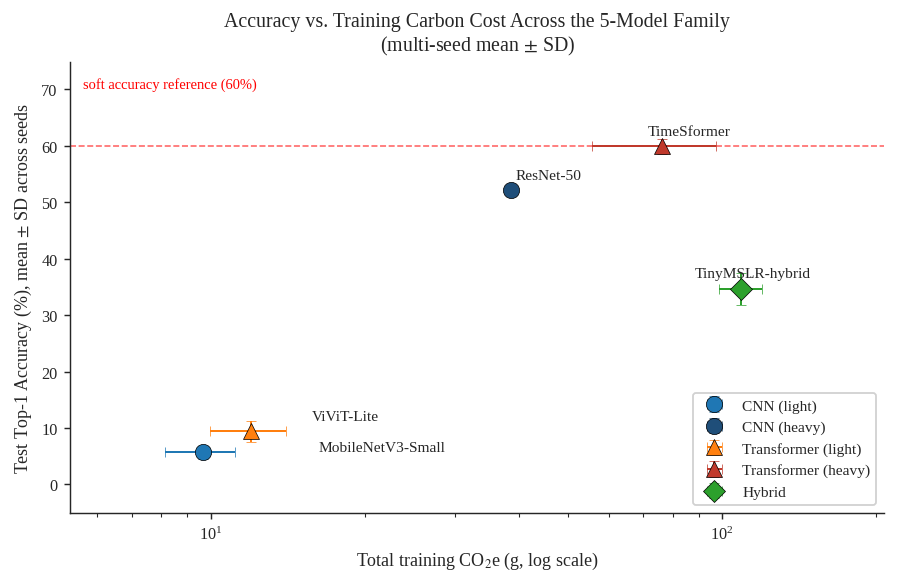

In [7]:
FAMILY_COLORS = {
    "CNN (light)": "#1f77b4",
    "CNN (heavy)": "#1f4e79",
    "Transformer (light)": "#ff7f0e",
    "Transformer (heavy)": "#c0392b",
    "Hybrid": "#2ca02c",
}
FAMILY_MARKERS = {
    "CNN (light)": "o",
    "CNN (heavy)": "o",
    "Transformer (light)": "^",
    "Transformer (heavy)": "^",
    "Hybrid": "D",
}
# Manual fallback offsets (points) if adjustText isn't available -- tuned once for this
# study's five-model family so labels clear the markers/error bars without needing the
# iterative solver. Given as (dx, dy) in points, passed to ax.annotate's textcoords="offset points".
MANUAL_LABEL_OFFSETS = {
    "MobileNetV3-Small": (10, -14),
    "ResNet-50": (10, 10),
    "ViViT-Lite": (10, -16),
    "TimeSformer": (-55, 12),
    "TinyMSLR-hybrid": (10, 10),
}

fig, ax = plt.subplots(figsize=(7.0, 4.6))
texts = []
point_x, point_y = [], []
for name, row in table1.iterrows():
    fam = row["Family"]
    ax.errorbar(
        row["CO2e mean (g)"], row["Top-1 mean (%)"],
        xerr=row["CO2e std (g)"], yerr=row["Top-1 std (pp)"],
        fmt=FAMILY_MARKERS[fam], color=FAMILY_COLORS[fam],
        markersize=9, capsize=3, elinewidth=1.1, markeredgecolor="black",
        markeredgewidth=0.4, label=fam, zorder=3,
    )
    point_x.append(row["CO2e mean (g)"])
    point_y.append(row["Top-1 mean (%)"])
    if ADJUST_TEXT_AVAILABLE:
        # Start each label with a small offset from its marker (not glued exactly on top of
        # it) -- adjustText then only needs to fine-tune from here, rather than relying on
        # point-repulsion alone to discover which direction to move.
        t = ax.text(row["CO2e mean (g)"] * 1.03, row["Top-1 mean (%)"] + 1.5, name,
                     fontsize=8.5, zorder=4)
        texts.append(t)
    else:
        dx, dy = MANUAL_LABEL_OFFSETS.get(name, (10, 10))
        ax.annotate(
            name, (row["CO2e mean (g)"], row["Top-1 mean (%)"]),
            textcoords="offset points", xytext=(dx, dy), fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75), zorder=4,
        )

if ADJUST_TEXT_AVAILABLE:
    # Passing the marker coordinates explicitly via x=/y= is what makes adjustText repel
    # labels away from THEIR OWN marker, not just away from each other -- without this,
    # isolated labels (nothing else nearby to collide with) never move off their marker.
    adjust_text(
        texts, x=point_x, y=point_y, ax=ax,
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, shrinkA=2, shrinkB=2),
        expand_points=(2.2, 2.4), expand_text=(1.4, 1.6),
        force_points=1.0, force_text=0.5, only_move={"points": "xy", "text": "xy"},
    )

ax.axhline(60, linestyle="--", color="red", linewidth=0.9, alpha=0.6, zorder=1)
ax.text(0.015, 0.965, "soft accuracy reference (60%)", color="red", fontsize=8,
        transform=ax.transAxes, ha="left", va="top")

ax.set_xscale("log")
co2_vals = table1["CO2e mean (g)"]
ax.set_xlim(co2_vals.min() * 0.55, co2_vals.max() * 1.9)  # headroom so labels near the
                                                            # rightmost/leftmost points have
                                                            # room to be pushed clear of markers
ax.set_xlabel("Total training CO$_2$e (g, log scale)")
ax.set_ylabel("Test Top-1 Accuracy (%), mean $\\pm$ SD across seeds")
ax.set_title("Accuracy vs. Training Carbon Cost Across the 5-Model Family\n(multi-seed mean $\\pm$ SD)")
ax.set_ylim(-5, max(table1["Top-1 mean (%)"]) + 15)  # headroom so labels/legend don't clip

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc="lower right", framealpha=0.9)
sns.despine(ax=ax)

fig.tight_layout()
save_figure(fig, "figure1_accuracy_vs_co2e_multiseed")
plt.show()


## 7. Figure 2 — Accuracy-per-Carbon Efficiency (eta_train, with error bars)

Extra right-hand margin (`set_xlim`) is added so the value labels at the end of each bar
never get clipped or collide with the plot edge, regardless of how wide the longest label is.

Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure2_eta_train_multiseed.png
Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure2_eta_train_multiseed.pdf


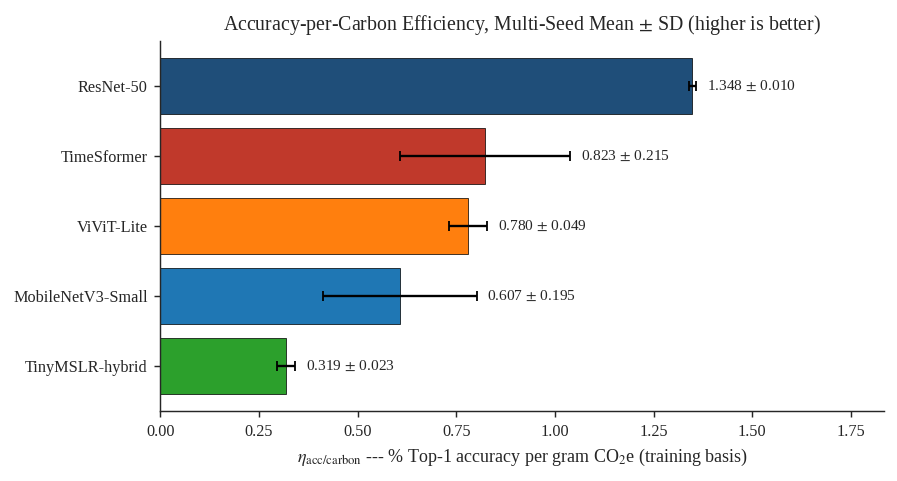

In [8]:
ranked = table1.sort_values("eta_train mean", ascending=True)

fig, ax = plt.subplots(figsize=(7.0, 3.8))
bar_colors = [FAMILY_COLORS[fam] for fam in ranked["Family"]]
bars = ax.barh(
    ranked.index, ranked["eta_train mean"],
    xerr=ranked["eta_train std"], color=bar_colors, capsize=3,
    edgecolor="black", linewidth=0.4,
)

max_label_extent = (ranked["eta_train mean"] + ranked["eta_train std"]).max()
ax.set_xlim(0, max_label_extent * 1.35)  # headroom so text labels never clip the axis edge

for bar, mean_val, std_val in zip(bars, ranked["eta_train mean"], ranked["eta_train std"]):
    ax.text(
        bar.get_width() + std_val + max_label_extent * 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{mean_val:.3f} $\\pm$ {std_val:.3f}", va="center", ha="left", fontsize=8.5,
    )

ax.set_xlabel(r"$\eta_{\mathrm{acc/carbon}}$ --- % Top-1 accuracy per gram CO$_2$e (training basis)")
ax.set_title(r"Accuracy-per-Carbon Efficiency, Multi-Seed Mean $\pm$ SD (higher is better)")
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "figure2_eta_train_multiseed")
plt.show()


## 8. Figure 3 — TinyMSLR-Hybrid Fusion Gate Collapse

Pulled directly from the hybrid's model card -- this is a single deterministic inspection of
the trained model's own learned weights, not something that needs (or benefits from) multi-seed
averaging in the same way the other figures do. Included here anyway for completeness /
single-source-of-truth figure generation.

Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure3_fusion_gate.png
Saved figure: /kaggle/working/green_report_aggregated/metadata_results/images/figure3_fusion_gate.pdf


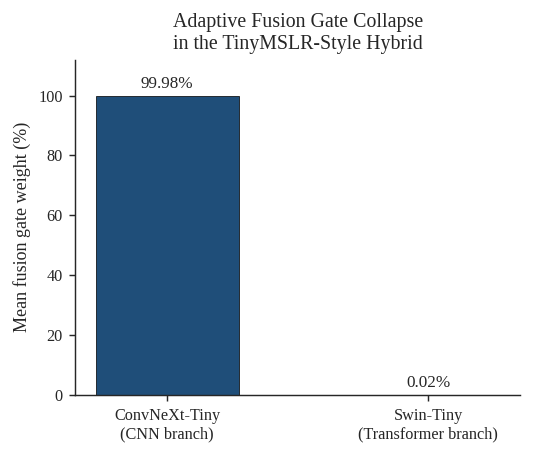

In [9]:
hybrid_card = MODEL_CARDS["tinymslr_hybrid_no_kd"]
gate_cnn = hybrid_card["mean_gate_weight_cnn"]
gate_transformer = hybrid_card["mean_gate_weight_transformer"]

fig, ax = plt.subplots(figsize=(4.2, 3.6))
bars = ax.bar(
    ["ConvNeXt-Tiny\n(CNN branch)", "Swin-Tiny\n(Transformer branch)"],
    [gate_cnn * 100, gate_transformer * 100],
    color=["#1f4e79", "#c0392b"], edgecolor="black", linewidth=0.4, width=0.55,
)
for bar, val in zip(bars, [gate_cnn, gate_transformer]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2.5,
            f"{val * 100:.2f}%", ha="center", fontsize=9.5)

ax.set_ylabel("Mean fusion gate weight (%)")
ax.set_ylim(0, 112)  # headroom above the tallest bar's text label
ax.set_title("Adaptive Fusion Gate Collapse\nin the TinyMSLR-Style Hybrid")
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "figure3_fusion_gate")
plt.show()


## 9. Deployment-Volume Sensitivity Table (η_life stability check)

Joins each model's `lifecycle_carbon_sensitivity` list (computed per-model, primary seed) into
one comparison table, and checks whether the efficiency ranking is stable across three plausible
deployment volumes (paper review Minor Issue #6) rather than trusting a single 100,000-inference
point estimate.

In [10]:
volume_rows = []
for tag, card in MODEL_CARDS.items():
    for entry in card["lifecycle_carbon_sensitivity"]:
        volume_rows.append({
            "Model": DISPLAY_NAMES[tag],
            "Deployment volume (inferences)": entry["deployment_volume_inferences"],
            "Lifecycle CO2e/inference (mg)": entry["lifecycle_co2_mg_per_inference"],
            "eta_life (%/g CO2e)": entry["eta_lifecycle_pct_per_g_co2e"],
        })

volume_df = pd.DataFrame(volume_rows)
volume_pivot = volume_df.pivot(index="Model", columns="Deployment volume (inferences)",
                                values="eta_life (%/g CO2e)")
volume_pivot = volume_pivot.reindex([DISPLAY_NAMES[t] for t in CONFIG.EXPECTED_MODEL_TAGS])

save_table(volume_pivot, "table2_deployment_volume_sensitivity")
display(volume_pivot)

# --- Ranking-stability check: is the #1 (and last-place) model the same at every volume? ---
print("\nRanking stability check (highest eta_life = rank 1) at each deployment volume:")
rank_by_volume = volume_pivot.rank(ascending=False, axis=0)
display(rank_by_volume)
save_table(rank_by_volume, "table2b_deployment_volume_rank_stability")

top_ranked_per_volume = volume_pivot.idxmax(axis=0)
bottom_ranked_per_volume = volume_pivot.idxmin(axis=0)
stable_top = top_ranked_per_volume.nunique() == 1
stable_bottom = bottom_ranked_per_volume.nunique() == 1
print(f"\nMost-efficient model stable across all volumes: {stable_top} "
      f"({top_ranked_per_volume.unique().tolist()})")
print(f"Least-efficient model stable across all volumes: {stable_bottom} "
      f"({bottom_ranked_per_volume.unique().tolist()})")


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table2_deployment_volume_sensitivity.csv


Deployment volume (inferences),10000,100000,1000000
Model,,,
MobileNetV3-Small,6794.125658,26362.398695,37026.752594
ResNet-50,11902.645696,56122.354443,89297.358397
ViViT-Lite,6762.928504,27430.519819,39502.545512
TimeSformer,6616.218630,26132.462292,37066.049927
TinyMSLR-hybrid,2842.306466,11734.703344,17077.564147



Ranking stability check (highest eta_life = rank 1) at each deployment volume:


Deployment volume (inferences),10000,100000,1000000
Model,,,
MobileNetV3-Small,2.0,3.0,4.0
ResNet-50,1.0,1.0,1.0
ViViT-Lite,3.0,2.0,2.0
TimeSformer,4.0,4.0,3.0
TinyMSLR-hybrid,5.0,5.0,5.0


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table2b_deployment_volume_rank_stability.csv

Most-efficient model stable across all volumes: True (['ResNet-50'])
Least-efficient model stable across all volumes: True (['TinyMSLR-hybrid'])


## 10. Accuracy-Threshold Sensitivity Table

Reports each model's primary-seed and multi-seed-mean top-1 against the 50/60/70% thresholds,
so the paper's deployment recommendation isn't resting on one unjustified single line
(paper review Minor Issue #7), and so it's visible when a model clears a threshold on one seed
but not on average (e.g. TimeSformer at the 60% line).

In [11]:
threshold_rows = []
for tag, card in MODEL_CARDS.items():
    mss = card.get("multi_seed_summary", {})
    row = {
        "Model": DISPLAY_NAMES[tag],
        "Top-1 primary seed (%)": pct(card["test_top1"]),
        "Top-1 mean across seeds (%)": pct(mss.get("test_top1_mean")),
        "Top-1 std (pp)": pct(mss.get("test_top1_std")),
    }
    for k, v in card.get("deployment_threshold_sensitivity", {}).items():
        row[k] = v
    # Also compute whether the SEED-MEAN clears each threshold, not just the primary seed --
    # this is what actually catches the TimeSformer-style marginal case.
    mean_top1 = mss.get("test_top1_mean")
    for t in (0.50, 0.60, 0.70):
        row[f"mean_clears_{int(t * 100)}pct"] = (
            bool(mean_top1 >= t) if mean_top1 is not None else None
        )
    threshold_rows.append(row)

threshold_df = pd.DataFrame(threshold_rows).set_index("Model")
save_table(threshold_df, "table3_accuracy_threshold_sensitivity")
display(threshold_df)

# --- Flag any model whose primary-seed threshold pass does NOT hold on the seed mean ---
for name, row in threshold_df.iterrows():
    for t in (50, 60, 70):
        primary = row.get(f"clears_{t}pct_threshold")
        mean_clears = row.get(f"mean_clears_{t}pct")
        if primary is True and mean_clears is False:
            print(f"NOTE: {name} clears the {t}% threshold on its primary seed but NOT on "
                  f"its {row['Top-1 mean across seeds (%)']:.2f}% multi-seed mean -- report "
                  "this explicitly in the paper rather than letting the single-run number stand.")


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table3_accuracy_threshold_sensitivity.csv


,Top-1 primary seed (%),Top-1 mean across seeds (%),Top-1 std (pp),clears_50pct_threshold,clears_60pct_threshold,clears_70pct_threshold,mean_clears_50pct,mean_clears_60pct,mean_clears_70pct
Model,,,,,,,,,
MobileNetV3-Small,6.60,5.70,1.10,False,False,False,False,False,False
ResNet-50,52.45,52.12,0.30,True,False,False,True,False,False
ViViT-Lite,11.57,9.39,1.90,False,False,False,False,False,False
TimeSformer,60.89,59.90,1.37,True,True,False,True,False,False
TinyMSLR-hybrid,32.86,34.68,2.85,False,False,False,False,False,False


NOTE: TimeSformer clears the 60% threshold on its primary seed but NOT on its 59.90% multi-seed mean -- report this explicitly in the paper rather than letting the single-run number stand.


## 11. Within-Family Marginal Carbon Cost per Accuracy Point (re-derived from means)

Recomputes the paper's Section 4.3 finding using multi-seed means instead of single-run figures,
to check whether "Transformer scaling costs roughly double the CNN family's marginal carbon
rate per accuracy point" survives repeated-seed measurement.

In [12]:
def marginal_cost(light_tag, heavy_tag):
    light = table1.loc[DISPLAY_NAMES[light_tag]]
    heavy = table1.loc[DISPLAY_NAMES[heavy_tag]]
    delta_acc = heavy["Top-1 mean (%)"] - light["Top-1 mean (%)"]
    delta_co2 = heavy["CO2e mean (g)"] - light["CO2e mean (g)"]
    return delta_acc, delta_co2, (delta_co2 / delta_acc if delta_acc else None)


cnn_delta_acc, cnn_delta_co2, cnn_marginal = marginal_cost(
    "mobilenet_v3_small_cnn_light", "resnet50_cnn_heavy")
tf_delta_acc, tf_delta_co2, tf_marginal = marginal_cost(
    "vivit_lite_transformer_light", "timesformer_base_transformer_heavy")

print("CNN family (MobileNetV3-Small -> ResNet-50), multi-seed means:")
print(f"  Delta accuracy: {cnn_delta_acc:.2f} points | Delta CO2e: {cnn_delta_co2:.2f} g "
      f"| marginal cost: {cnn_marginal:.4f} g CO2e/point")

print("\nTransformer family (ViViT-Lite -> TimeSformer), multi-seed means:")
print(f"  Delta accuracy: {tf_delta_acc:.2f} points | Delta CO2e: {tf_delta_co2:.2f} g "
      f"| marginal cost: {tf_marginal:.4f} g CO2e/point")

ratio = tf_marginal / cnn_marginal if cnn_marginal else None
print(f"\nTransformer family's marginal cost is {ratio:.2f}x the CNN family's "
      "(paper originally reported ~2x from a single run -- compare against that here).")

marginal_cost_df = pd.DataFrame([
    {"Family": "CNN (MobileNetV3-Small -> ResNet-50)", "Delta accuracy (pts)": cnn_delta_acc,
     "Delta CO2e (g)": cnn_delta_co2, "Marginal cost (g CO2e/point)": cnn_marginal},
    {"Family": "Transformer (ViViT-Lite -> TimeSformer)", "Delta accuracy (pts)": tf_delta_acc,
     "Delta CO2e (g)": tf_delta_co2, "Marginal cost (g CO2e/point)": tf_marginal},
]).set_index("Family")
save_table(marginal_cost_df, "table5_within_family_marginal_cost")


CNN family (MobileNetV3-Small -> ResNet-50), multi-seed means:
  Delta accuracy: 46.42 points | Delta CO2e: 28.99 g | marginal cost: 0.6245 g CO2e/point

Transformer family (ViViT-Lite -> TimeSformer), multi-seed means:
  Delta accuracy: 50.51 points | Delta CO2e: 64.40 g | marginal cost: 1.2749 g CO2e/point

Transformer family's marginal cost is 2.04x the CNN family's (paper originally reported ~2x from a single run -- compare against that here).
Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table5_within_family_marginal_cost.csv


PosixPath('/kaggle/working/green_report_aggregated/metadata_results/tables/table5_within_family_marginal_cost.csv')

## 12. Signer-Independence and Hardware/Software Environment (shared across all 5 models)

Both checks were run independently inside each of the five notebooks; since all five draw on the
same cached splits and ran on the same Kaggle session type, this cell simply verifies that all
five reports agree (they should -- if they don't, that itself is worth flagging) rather than
re-deriving anything new.

In [13]:
print("=== Signer-independence report (should be identical across all 5 models) ===")
signer_reports = {tag: card.get("signer_independence_report") for tag, card in MODEL_CARDS.items()}
signer_reports_str = {tag: json.dumps(r, sort_keys=True) for tag, r in signer_reports.items()}
all_identical = len(set(signer_reports_str.values())) == 1
print(f"All 5 signer-independence reports identical: {all_identical}\n")
signer_df = pd.DataFrame(signer_reports).T
display(signer_df)
save_table(signer_df, "table6_signer_independence")

print("\n=== Hardware/software environment (should be identical across all 5 models) ===")
hw_reports = {tag: card.get("hardware_software_environment") for tag, card in MODEL_CARDS.items()}
hw_reports_str = {tag: json.dumps(r, sort_keys=True) for tag, r in hw_reports.items()}
all_identical_hw = len(set(hw_reports_str.values())) == 1
print(f"All 5 hardware/software environments identical: {all_identical_hw}\n")
hw_df = pd.DataFrame(hw_reports).T
display(hw_df)
save_table(hw_df, "table7_hardware_software_environment")

if not all_identical or not all_identical_hw:
    print("\nWARNING: not all five notebooks ran under identical conditions -- flag this in the "
          "paper's Section 3.4.1 rather than silently reporting one model's environment as if "
          "it applied to all five.")


=== Signer-independence report (should be identical across all 5 models) ===
All 5 signer-independence reports identical: True



,signer_column_found,signer_id_source,n_signers_train,n_signers_val,n_signers_test,n_signers_overlap_train_val,n_signers_overlap_train_test,n_signers_overlap_val_test,is_signer_disjoint
mobilenet_v3_small_cnn_light,Participant ID,csv_column,35,5,11,0,0,0,True
resnet50_cnn_heavy,Participant ID,csv_column,35,5,11,0,0,0,True
vivit_lite_transformer_light,Participant ID,csv_column,35,5,11,0,0,0,True
timesformer_base_transformer_heavy,Participant ID,csv_column,35,5,11,0,0,0,True
tinymslr_hybrid_no_kd,Participant ID,csv_column,35,5,11,0,0,0,True


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table6_signer_independence.csv

=== Hardware/software environment (should be identical across all 5 models) ===
All 5 hardware/software environments identical: True



,torch_version,cuda_version_torch_built_with,cudnn_version,python_version,platform,cpu_count_logical,gpu_available,gpu_name,gpu_count,gpu_total_memory_gb,gpu_capability,ram_total_gb
mobilenet_v3_small_cnn_light,2.10.0+cu128,12.8,91002,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,4,True,Tesla T4,2,14.56,7.5,31.35
resnet50_cnn_heavy,2.10.0+cu128,12.8,91002,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,4,True,Tesla T4,2,14.56,7.5,31.35
vivit_lite_transformer_light,2.10.0+cu128,12.8,91002,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,4,True,Tesla T4,2,14.56,7.5,31.35
timesformer_base_transformer_heavy,2.10.0+cu128,12.8,91002,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,4,True,Tesla T4,2,14.56,7.5,31.35
tinymslr_hybrid_no_kd,2.10.0+cu128,12.8,91002,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,4,True,Tesla T4,2,14.56,7.5,31.35


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table7_hardware_software_environment.csv


## 13. Peak Memory & Latency Summary (paper review Minor Issue #10)

In [14]:
mem_latency_rows = []
for tag, card in MODEL_CARDS.items():
    mem_latency_rows.append({
        "Model": DISPLAY_NAMES[tag],
        "Peak train GPU mem (GB)": card.get("peak_train_gpu_memory_gb"),
        "Peak inference GPU mem (GB)": card.get("peak_inference_gpu_memory_gb"),
        "Latency per clip (ms)": card.get("latency_ms_per_clip_inference"),
    })

mem_latency_df = pd.DataFrame(mem_latency_rows).set_index("Model")
save_table(mem_latency_df, "table4_memory_latency")
display(mem_latency_df)


Saved table: /kaggle/working/green_report_aggregated/metadata_results/tables/table4_memory_latency.csv


,Peak train GPU mem (GB),Peak inference GPU mem (GB),Latency per clip (ms)
Model,,,
MobileNetV3-Small,0.363,0.349,21.026757
ResNet-50,1.603,1.602,48.023740
ViViT-Lite,0.820,0.354,24.175169
TimeSformer,2.914,1.385,139.961213
TinyMSLR-hybrid,3.084,2.432,164.726339


## 14. Everything in One Bundle

Combines every table produced above into a single JSON bundle in `metadata_results/` (one level
up from `tables/`) so it's easy to hand off to the paper-writing pass without hunting through
several separate CSVs.

In [15]:
bundle = {
    "table1_multiseed_comparison": table1.reset_index().to_dict(orient="records"),
    "table2_deployment_volume_sensitivity": volume_pivot.reset_index().to_dict(orient="records"),
    "table3_accuracy_threshold_sensitivity": threshold_df.reset_index().to_dict(orient="records"),
    "table4_memory_latency": mem_latency_df.reset_index().to_dict(orient="records"),
    "table5_within_family_marginal_cost": marginal_cost_df.reset_index().to_dict(orient="records"),
    "signer_independence_identical_across_models": all_identical,
    "hardware_software_identical_across_models": all_identical_hw,
    "cnn_family_marginal_co2_per_point": cnn_marginal,
    "transformer_family_marginal_co2_per_point": tf_marginal,
    "transformer_to_cnn_marginal_ratio": ratio,
}

bundle_path = CONFIG.METADATA_DIR / "aggregated_results_bundle.json"
with open(bundle_path, "w") as f:
    json.dump(bundle, f, indent=2, default=str)

print(f"Saved: {bundle_path}")
print(f"\nFinal output layout under: {CONFIG.METADATA_DIR}")
for sub in (CONFIG.TABLES_DIR, CONFIG.IMAGES_DIR):
    print(f"\n{sub.name}/")
    for p in sorted(sub.iterdir()):
        print(f"  {p.name}")
print(f"\n{bundle_path.name}  (in {CONFIG.METADATA_DIR})")


Saved: /kaggle/working/green_report_aggregated/metadata_results/aggregated_results_bundle.json

Final output layout under: /kaggle/working/green_report_aggregated/metadata_results

tables/
  table1_multiseed_comparison.csv
  table1_multiseed_comparison.md
  table2_deployment_volume_sensitivity.csv
  table2b_deployment_volume_rank_stability.csv
  table3_accuracy_threshold_sensitivity.csv
  table4_memory_latency.csv
  table5_within_family_marginal_cost.csv
  table6_signer_independence.csv
  table7_hardware_software_environment.csv

images/
  figure1_accuracy_vs_co2e_multiseed.pdf
  figure1_accuracy_vs_co2e_multiseed.png
  figure2_eta_train_multiseed.pdf
  figure2_eta_train_multiseed.png
  figure3_fusion_gate.pdf
  figure3_fusion_gate.png

aggregated_results_bundle.json  (in /kaggle/working/green_report_aggregated/metadata_results)


## 15. Notes for the Paper

- **Output folder to hand off:** `CONFIG.METADATA_DIR` (i.e. `.../green_report_aggregated/metadata_results/`)
  contains everything — `tables/*.csv` + `table1_multiseed_comparison.md`, `images/*.png` +
  `images/*.pdf`, and one top-level `aggregated_results_bundle.json`. Zip and share this one
  folder rather than hunting through individual notebook outputs.
- **Figures are LaTeX/IEEE-ready:** each figure is saved as both a 300-DPI PNG (for quick
  viewing/slides) and a vector PDF (`\includegraphics{images/figure1_...pdf}` drops straight
  into an IEEE two-column paper without re-rasterizing). Fonts use a Times-like serif stack via
  `mathtext.fontset="stix"`; flip `text.usetex` to `True` in Section 1 if your environment has a
  working LaTeX install and you want the exact system LaTeX font instead.
- **No overlapping label text:** Figure 1's five model-name labels are placed with `adjustText`
  when available (falls back to tuned manual offsets otherwise); Figure 2's value labels get
  explicit x-axis headroom so they never clip the plot edge.
- **Table 1** above (Section 4) replaces the original single-run table with multi-seed mean ± SD
  for every model — copy `tables/table1_multiseed_comparison.md` directly into the paper.
- **Table 2** (deployment-volume sensitivity) answers whether the lifecycle efficiency ranking
  is stable across plausible deployment scales — report both the table and the explicit
  stability verdict printed in Section 9.
- **Table 3** (accuracy-threshold sensitivity) will surface any model — TimeSformer, in this
  study's own data — that clears a threshold on its primary seed but not on its multi-seed mean.
  State this explicitly in Section 4.1/5.2 rather than letting the single-run number stand
  unqualified.
- **Table 5's** marginal-cost ratio is the number to cite when re-checking whether the paper's
  "Transformer family costs ~2x the CNN family's marginal carbon rate per accuracy point"
  finding survives repeated-seed measurement.
- **Tables 6-7's** identical-environment/signer-independence check is what lets Section 3.1.1 and
  3.4.1 state, with evidence rather than assumption, that all five models share one split and
  one hardware environment.
- Nothing in this notebook trains a model or measures new energy — it is pure aggregation of
  the five upstream model cards, so it is inexpensive to re-run any time a model card changes.